[    0.7 s] running OBS ... done in 0.0 s
[    0.7 s] running DBCCA ... done in 359.1 s
[  359.8 s] running ISIMIP3BASD ... done in 605.6 s
[  965.4 s] running SRDRN-QDM ... done in 427.5 s
[ 1393.0 s] running GCM ... done in 92.3 s
[ 1485.4 s] islands loaded in 0.1 s
[ 1487.2 s] climatologies done in 1.7 s
[ 1487.2 s] drawing fig_H1_main ... 

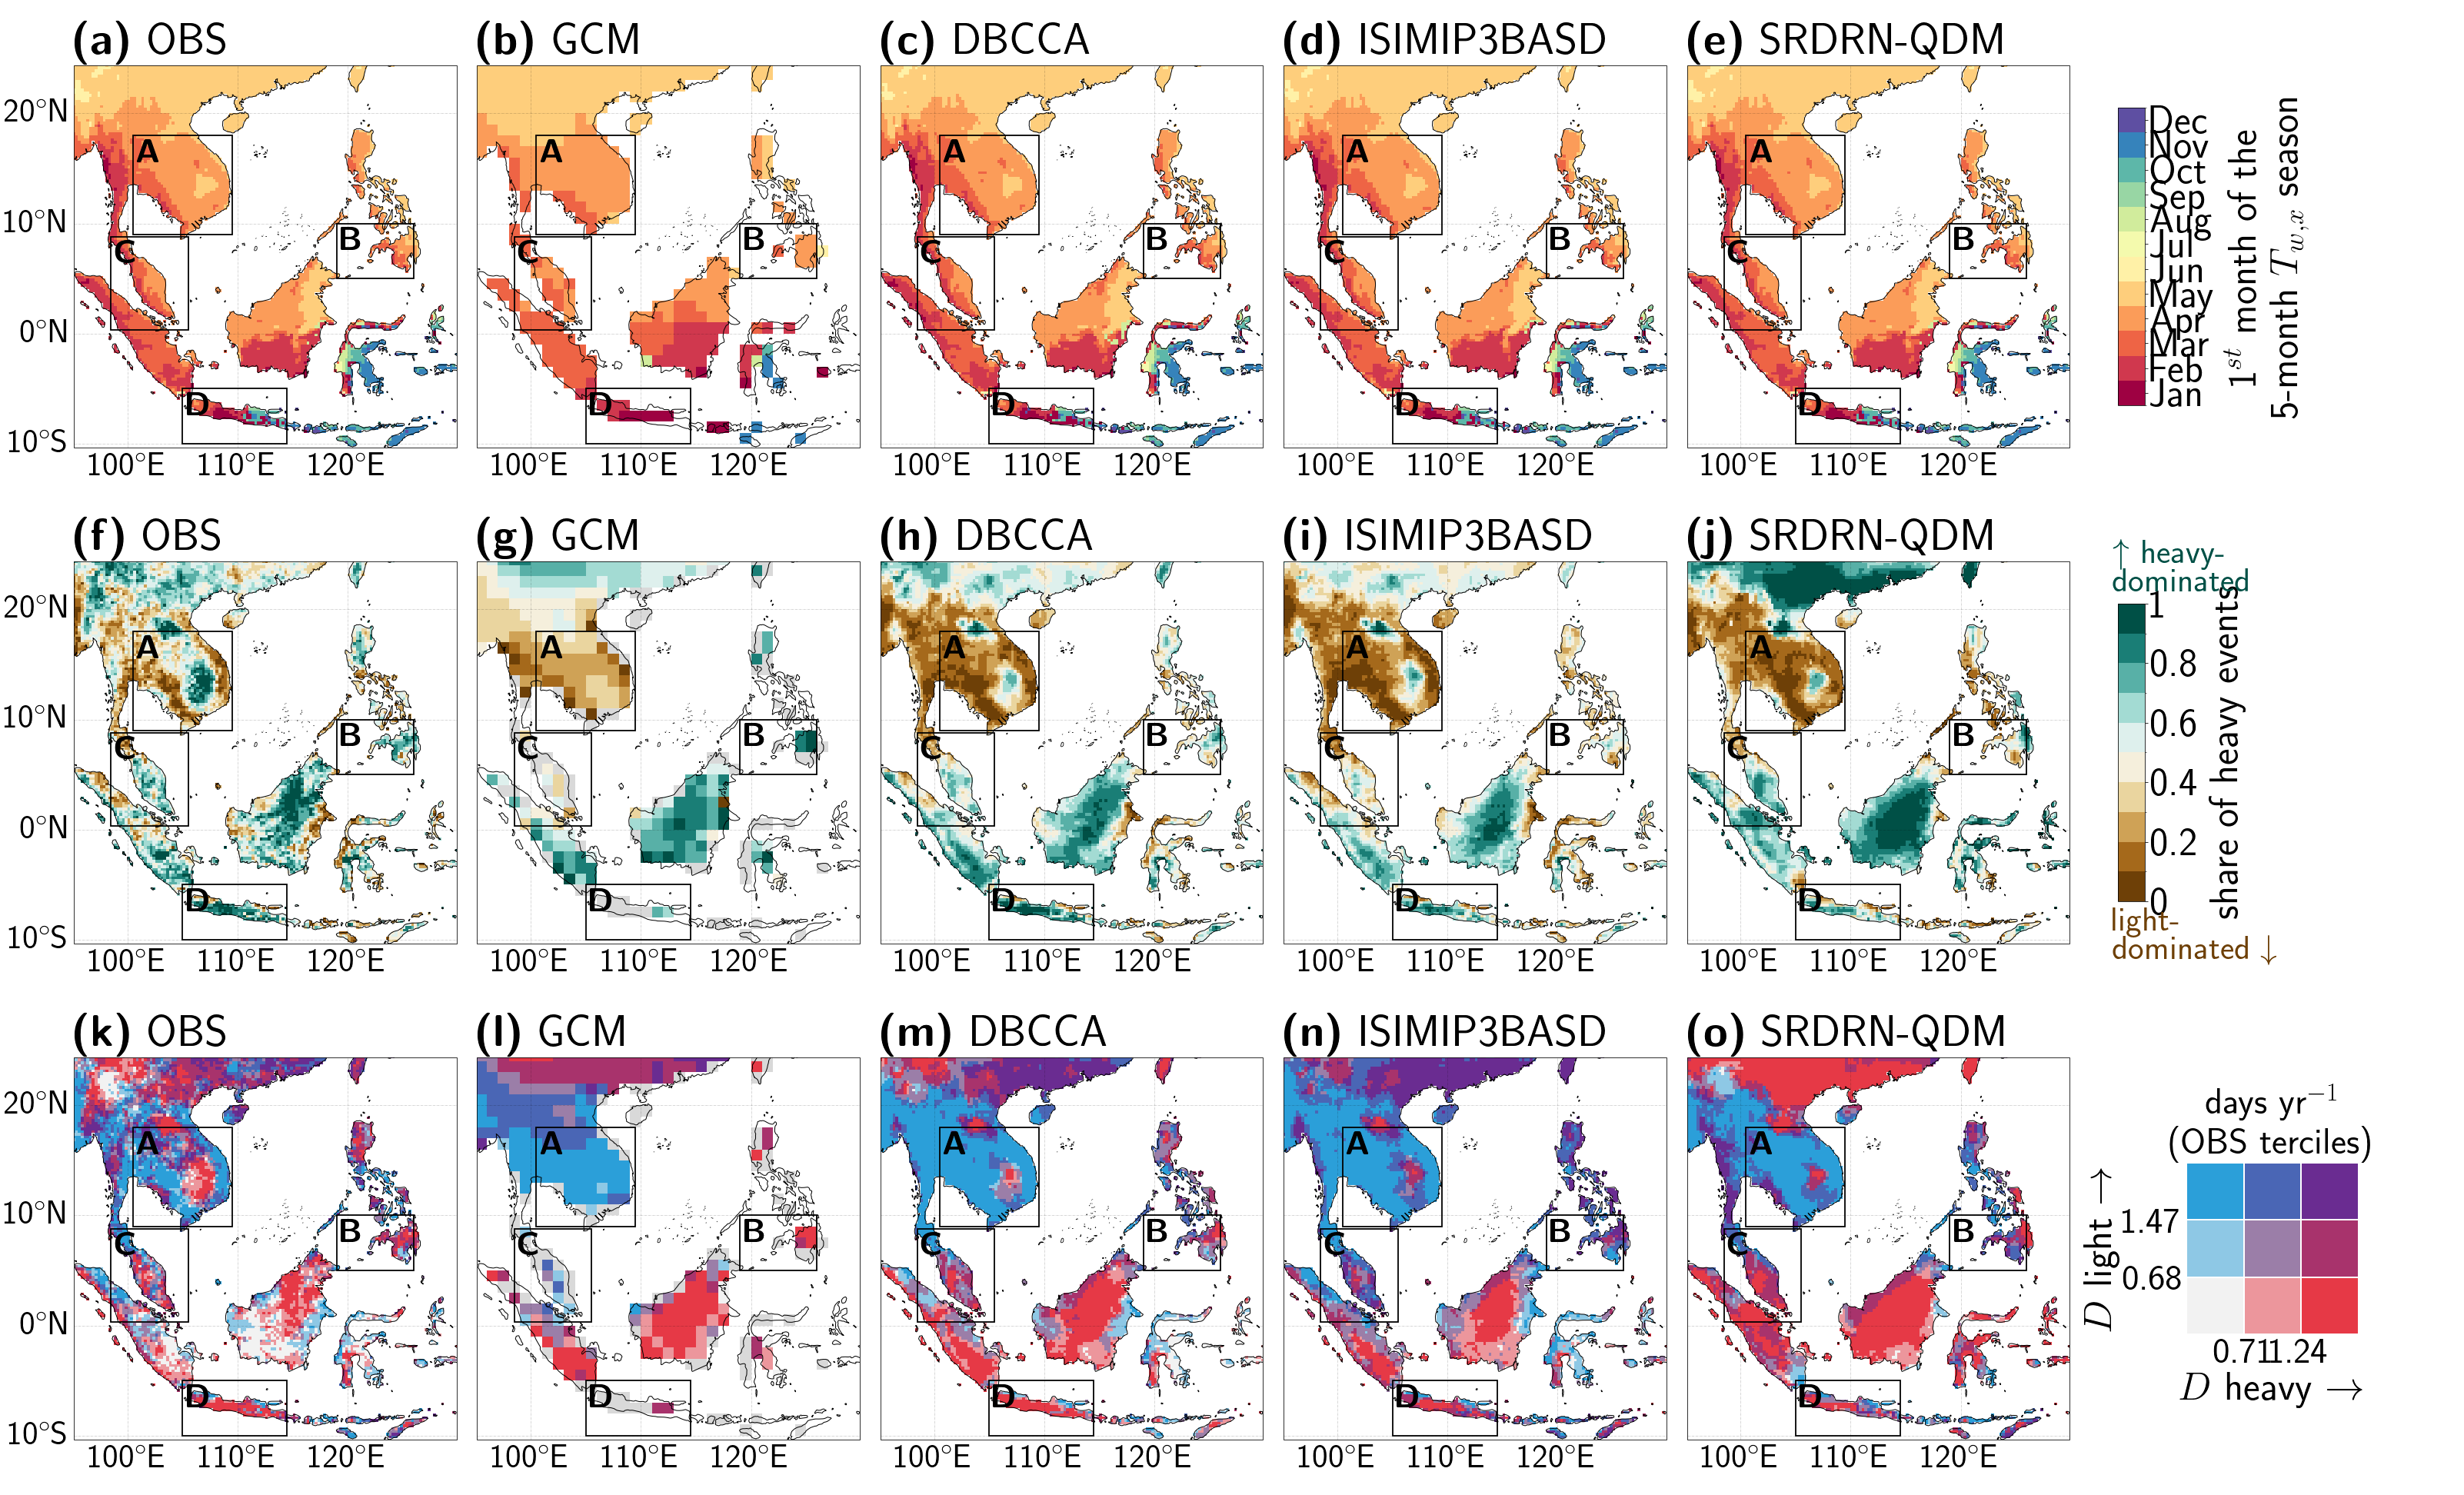

done in 3.1 s
[ 1490.3 s] drawing fig_S_H1 ... 

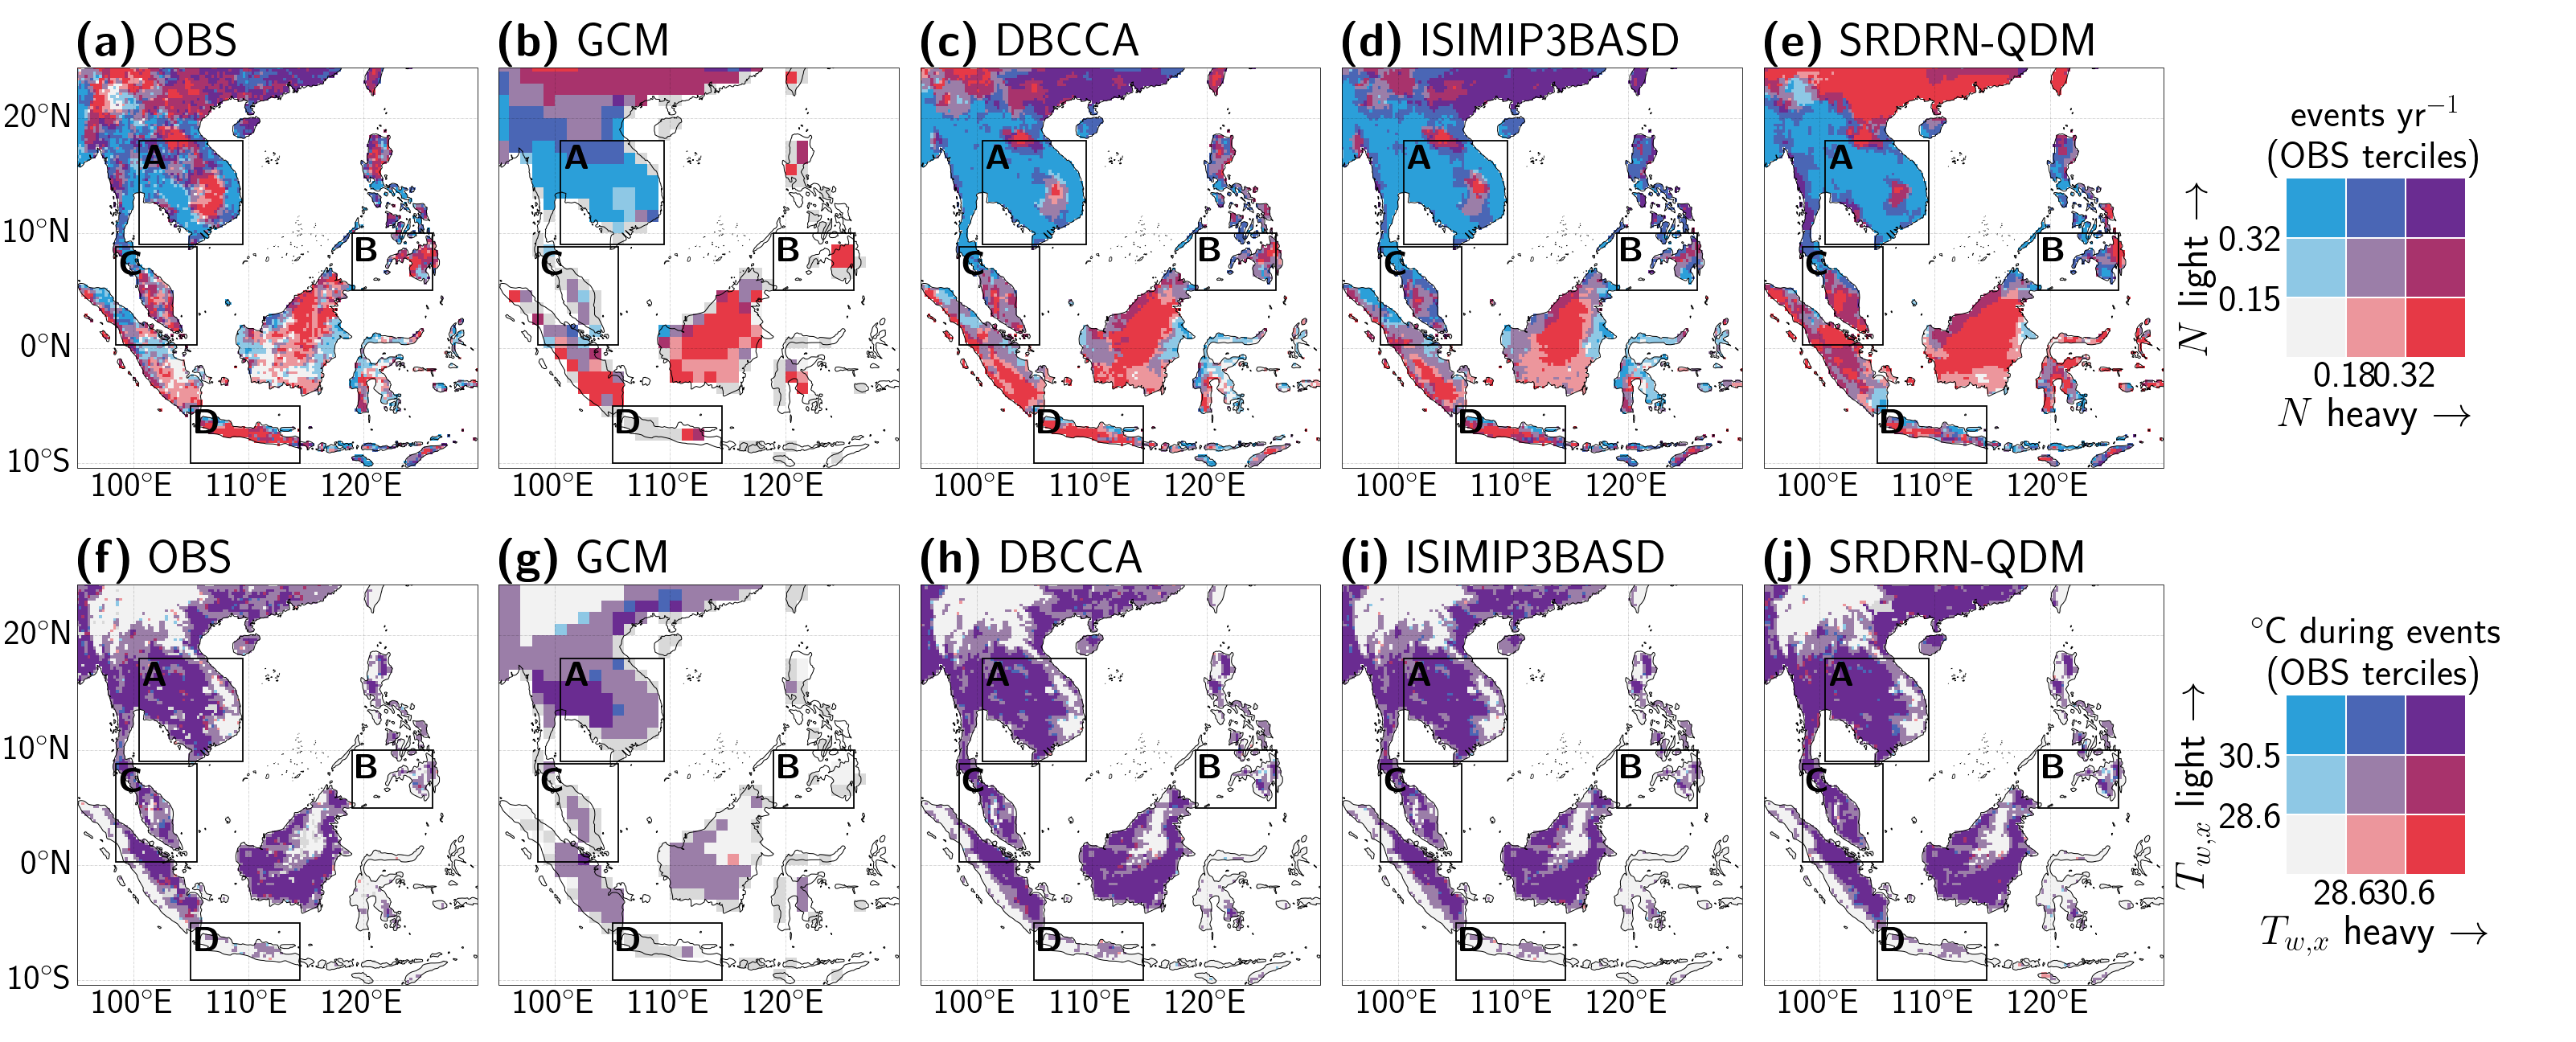

done in 1.6 s
[ 1491.8 s] TOTAL


In [2]:
import warnings; warnings.filterwarnings('ignore')
import os, glob, time, gc, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, matplotlib.colors as mcolors, cartopy.crs as ccrs, cartopy.io.shapereader as shpr
from concurrent.futures import ThreadPoolExecutor; from matplotlib.patches import Rectangle; from matplotlib.ticker import FixedLocator, FuncFormatter
from IPython import get_ipython; get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
T0 = time.time(); tk = lambda s_: print(f'[{time.time()-T0:7.1f} s] {s_}', flush=True)
# ---------------- CONFIG ----------------
ROOT, SSP, HIST, VARS = r"D:/G_data", 'ssp126', ('1981', '2014'), ['tasmax', 'hurs', 'pr']
OBSF = {'tasmax': f"{ROOT}/obs-SEA/SEA-mswx-tasmax-1981-end2014.nc", 'hurs': f"{ROOT}/obs-SEA/SEA-mswx-rh-1981-end2014.nc", 'pr': f"{ROOT}/obs-SEA/SEA-mswep-pr-1981-end2014.nc"}
PATH = {'DBCCA': ROOT + "/out-DBCCA-overSEA/dbcca_{v}_combined_hist" + SSP + "_{m}.nc", 'ISIMIP3BASD': ROOT + "/out-BASD-ssp-orig/basd_{v}_combined_hist" + SSP + "_1981-2100_df4_{m}.nc",
        'SRDRN-QDM': ROOT + "/out-SRDRN-QDM-2100/srdrn_{v}_combined_hist" + SSP + "_{m}.nc", 'GCM': ROOT + "/CMIP6-histssp-input/hist" + SSP + "/{v}_combined_hist" + SSP + "_{m}.nc"}
PRODS = ['DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM', 'GCM']
MODS = ['ACCESS-CM2','ACCESS-ESM1-5','CMCC-CM2-SR5','CMCC-ESM2','CanESM5','EC-Earth3','EC-Earth3-Veg','FGOALS-g3','GFDL-ESM4','INM-CM5-0','IPSL-CM6A-LR','KACE-1-0-G','MIROC6','MPI-ESM1-2-HR','MRI-ESM2-0','NorESM2-MM','TaiESM1']
NM, PQ, MINLEN, L, RBIN, LANDRES, CLS = 5, 90, 3, 3, [1., 5., 20.], '50m', {'light': 1, 'heavy': 3}
NJ, CH = min(8, os.cpu_count() or 4), 2000                                       # threads | cells per chunk (~0.6 GB RAM per thread)
REDO, USETEX, FS, ISP = False, True, 48, r"D:/G_data/paper-SRDRN/islands/islands"
GROUPS = {'fig_H1_main': ['onset', 'shareN', 'bivD'], 'fig_S_H1': ['bivN', 'bivT']}; COMBINE = True
CORN = dict(none='#f2f2f2', light='#2B9FD9', heavy='#E63946', both='#6A2C91'); HRP0 = ['DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM']
BMET = {'bivN': ('HWN', r'$N$', r'events yr$^{-1}$'), 'bivD': ('HWF', r'$D$', r'days yr$^{-1}$'), 'bivT': ('TW', r'$T_{w,x}$', r'$^{\circ}$C during events')}
SHR = {'shareN': ('HWN', 'N', np.round(np.arange(0, 1.01, .1), 2))}
KEYS = [f'{m}_{c}' for m in ('HWN', 'HWF', 'HWI') for c in ('light', 'heavy')] + ['q90', 'onset']
BOXES = {'A Mekong': dict(lon=(100.5, 109.5), lat=(9.0, 18.0)), 'B Mindanao': dict(lon=(119.0, 126.0), lat=(5.0, 10.0)), 'C Pen. Malaysia': dict(lon=(98.5, 105.5), lat=(0.3, 8.8)), 'D Java': dict(lon=(105.0, 114.5), lat=(-10.0, -5.0))}
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
# ---------------- LaTeX check ----------------
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}$'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS, 'axes.titlesize': FS+2, 'axes.labelsize': FS, 'xtick.labelsize': FS-4, 'ytick.labelsize': FS-4})
bf = (lambda s_: r'\textbf{' + s_ + '}') if USETEX else (lambda s_: s_); ARR = r'$\rightarrow$' if USETEX else '->'
# ---------------- I/O utils ----------------
def std_(ds):
    ren = {a: b for a, b in [('latitude', 'lat'), ('longitude', 'lon'), ('Latitude', 'lat'), ('Longitude', 'lon')] if a in ds.dims or a in ds.coords}; ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
def NL(d):
    cal = d.time.dt.calendar
    if cal in ('noleap', '365_day'): return d
    return d.convert_calendar('noleap', align_on='year', missing=np.nan) if cal == '360_day' else d.convert_calendar('noleap', align_on='date')
def fx(da, v):
    u = str(da.attrs.get('units', '')).lower().replace(' ', ''); s = da.isel(time=slice(0, 366))
    if v == 'tasmax' and (u in ('k', 'kelvin') or float(s.min()) > 100): da = da - 273.15
    elif v == 'pr' and (u in ('kgm-2s-1', 'kg/m2/s') or 0 < float(s.max()) < 0.01): da = da*86400.
    elif v == 'hurs' and float(s.max()) <= 1.5: da = da*100.
    return da
def landgrid(la, lo):
    import shapely.geometry as sgeom; from shapely.prepared import prep; from shapely.ops import unary_union
    pl = prep(unary_union(list(shpr.Reader(shpr.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries()))); x = ((np.asarray(lo)+180.) % 360.) - 180.; X, Y = np.meshgrid(x, np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a, b)) for a, b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
LMK = globals().get('LMK', {})
def lm(la, lo):
    k = (la.size, lo.size, round(float(la[0]), 3), round(float(lo[0]), 3))
    if k not in LMK: LMK[k] = landgrid(la, lo)
    return LMK[k]
def stull(Tc, R):
    R = np.clip(R, 5., 99.5); return (Tc*np.arctan(0.151977*np.sqrt(R+8.313659)) + np.arctan(Tc+R) - np.arctan(R-1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
samegrid = lambda la, lo, G: la.size == G['H'] and lo.size == G['W'] and np.allclose(la, G['lat'], atol=1e-3) and np.allclose(lo, G['lon'], atol=1e-3)
def load3(fs, G0=None):
    A = {}
    for v in VARS:
        d = std_(xr.open_dataset(fs[v], use_cftime=True))
        vn = v if v in d.data_vars else next((x for x in (['rh', 'relative_humidity'] if v == 'hurs' else []) if x in d.data_vars), next(x for x in d.data_vars if d[x].ndim == 3))
        A[v] = fx(NL(d[vn].sel(time=slice(*HIST))).astype('float32').transpose('time', 'lat', 'lon').load(), v); d.close()
    ky = {v: pd.MultiIndex.from_arrays([A[v].time.dt.year.values, A[v].time.dt.dayofyear.values]) for v in VARS}; com = ky['tasmax'].intersection(ky['hurs']).intersection(ky['pr'])
    for v in VARS: A[v] = A[v].isel(time=np.flatnonzero(ky[v].isin(com)))
    la, lo = A['tasmax'].lat.values.astype('f8'), A['tasmax'].lon.values.astype('f8')
    for v in ('hurs', 'pr'):
        if not (A[v].lat.size == la.size and A[v].lon.size == lo.size and np.allclose(A[v].lat, la, atol=1e-3) and np.allclose(A[v].lon, lo, atol=1e-3)): A[v] = A[v].reindex(lat=la, lon=lo, method='nearest')
    same = G0 is not None and samegrid(la, lo, G0); land = G0['land2d'] if same else lm(la, lo); fin = np.ones(land.shape, bool)
    for v in VARS: fin &= np.isfinite(A[v].values).mean(0) >= .9
    VI = np.flatnonzero((land & fin).ravel()); nt = A['tasmax'].sizes['time']; X = {v: np.ascontiguousarray(A[v].values.reshape(nt, -1)[:, VI].T) for v in VARS}
    YR, MO = A['tasmax'].time.dt.year.values.astype('i4'), A['tasmax'].time.dt.month.values.astype('i4'); del A; gc.collect()
    return X, dict(lat=la, lon=lo, H=la.size, W=lo.size, VI=VI, land2d=land, same=same), YR, MO
# ---------------- detection on one chunk of cells (independent -> parallel) ----------------
def hwchunk(tx, rh, PR, M0, yi, NY):
    TW = stull(tx, rh); n, T = TW.shape; r_ = np.arange(n)
    MTW = np.stack([np.nanmean(TW[:, M0 == m], 1) for m in range(12)], 1); cs_ = np.concatenate([MTW, MTW[:, :NM-1]], 1); ons = np.nanargmax(np.stack([cs_[:, i:i+NM].mean(1) for i in range(12)], 1), 1)
    INS = np.zeros((n, 12), bool); INS[r_[:, None], (ons[:, None] + np.arange(NM)) % 12] = True; SD = INS[:, M0]
    V = SD & np.isfinite(TW); kq = V.sum(1); A = np.sort(np.where(V, TW, np.inf), 1); del V           # vectorised in-season q90 (= np.nanpercentile 'linear')
    pos = (np.maximum(kq, 1) - 1)*PQ/100.; lo = np.floor(pos).astype(int); hi = np.minimum(lo + 1, np.maximum(kq - 1, 0))
    with np.errstate(invalid='ignore'): q = (A[r_, lo] + (A[r_, hi] - A[r_, lo])*(pos - lo)).astype('f4')
    q[kq == 0] = np.nan; del A
    dd = np.diff(np.pad(((TW > q[:, None]) & SD).astype(np.int8), ((0, 0), (1, 1))), axis=1)
    c, s = np.nonzero(dd == 1); _, e = np.nonzero(dd == -1); del dd, SD; du = e - s; k = du >= MINLEN; c, s, du = c[k], s[k], du[k]
    mx = np.full(c.size, -1., 'f4')
    for kk in range(-L, L+1): t = s + kk; ok = (t >= 0) & (t < T); mx[ok] = np.fmax(mx[ok], PR[c[ok], t[ok]])
    cls = np.digitize(mx, RBIN).astype('i1'); cls[mx < 0] = -1
    CS = np.cumsum(np.nan_to_num(TW - q[:, None]), axis=1, dtype='f8'); es = CS[c, s + du - 1] - np.where(s > 0, CS[c, np.maximum(s - 1, 0)], 0.); del CS, TW
    ey = yi[s]; out = {}
    for cn, cv in CLS.items():
        m = cls == cv; idx = ey[m]*n + c[m]; N = np.bincount(idx, minlength=NY*n).reshape(NY, n).astype('f4'); F = np.bincount(idx, du[m], NY*n).reshape(NY, n).astype('f4')
        with np.errstate(invalid='ignore', divide='ignore'): I = (np.bincount(idx, es[m], NY*n).reshape(NY, n)/np.where(F > 0, F, np.nan)).astype('f4')
        out[f'HWN_{cn}'], out[f'HWF_{cn}'], out[f'HWI_{cn}'] = N, F, I
    return out, q, ons
def uf(z, G):
    if z.ndim == 1: o = np.full(G['H']*G['W'], np.nan, 'f4'); o[G['VI']] = z; return o.reshape(G['H'], G['W'])
    o = np.full((z.shape[0], G['H']*G['W']), np.nan, 'f4'); o[:, G['VI']] = z; return o.reshape(z.shape[0], G['H'], G['W'])
def run1(fs, G0):
    X, G, YR, MO = load3(fs, G0); M0 = MO - 1; YRU = np.unique(YR); yi = np.searchsorted(YRU, YR); n = X['tasmax'].shape[0]
    job = lambda ab: hwchunk(X['tasmax'][ab[0]:ab[1]], X['hurs'][ab[0]:ab[1]], X['pr'][ab[0]:ab[1]], M0, yi, YRU.size)
    with ThreadPoolExecutor(NJ) as ex: R = list(ex.map(job, [(i, min(i + CH, n)) for i in range(0, n, CH)]))
    out = {k: np.concatenate([r[0][k] for r in R], 1) for k in R[0][0]}; q = np.concatenate([r[1] for r in R]); ons = np.concatenate([r[2] for r in R]); del X, R; gc.collect()
    ds = xr.Dataset({k: (('time', 'lat', 'lon'), uf(v_, G)) for k, v_ in out.items()}, coords={'time': YRU, 'lat': G['lat'], 'lon': G['lon']})
    ds['q90'] = (('lat', 'lon'), uf(q, G)); ds['onset'] = (('lat', 'lon'), uf(ons.astype('f4') + 1, G)); return dict(ds=ds, G=G)
def load_isl(p):
    fs = sorted(glob.glob(os.path.join(p, '**', '*.shp'), recursive=True)) if os.path.isdir(p) else [p if p.lower().endswith('.shp') else p + '.shp']; G_ = []
    for f in fs:
        try:
            import geopandas as gpd; d = gpd.read_file(f)
            if d.crs is not None and d.crs.to_epsg() != 4326: d = d.to_crs(4326)
            G_ += [g for g in d.geometry if g is not None and not g.is_empty]
        except ImportError: G_ += [g for g in shpr.Reader(f).geometries() if g is not None and not g.is_empty]
    return G_
# ---------------- STEP 1: compound metrics per product (cached in RAM) ----------------
RESC, ERR = globals().get('RESC', {}), {}
t_ = time.time(); print(f'[{t_-T0:7.1f} s] running OBS ...', end=' ', flush=True)
if ('OBS', 'obs') not in RESC or REDO: RESC[('OBS', 'obs')] = run1(OBSF, None)
print(f'done in {time.time()-t_:.1f} s', flush=True); OBSG = RESC[('OBS', 'obs')]['G']
for p in PRODS:
    t_ = time.time(); print(f'[{t_-T0:7.1f} s] running {p} ...', end=' ', flush=True)
    for m in MODS:
        fs = {v: PATH[p].format(v=v, m=m) for v in VARS}
        if ((p, m) in RESC and not REDO) or not all(os.path.exists(f) for f in fs.values()): continue
        try: RESC[(p, m)] = run1(fs, OBSG)
        except Exception as e: ERR[(p, m)] = f'{type(e).__name__}: {e}'
        gc.collect()
    print(f'done in {time.time()-t_:.1f} s', flush=True)
# ---------------- STEP 2: islands + grids ----------------
t_ = time.time(); ISL = globals().get('ISL') or load_isl(ISP); ISL_P = [g for g in ISL if g.geom_type not in ('Point', 'MultiPoint')]; tk(f'islands loaded in {time.time()-t_:.1f} s')
MODS_ = {p: sorted(m for (pp, m) in RESC if pp == p) for p in ['GCM'] + HRP0}; HRP = [p for p in HRP0 if MODS_[p]]
SRCS = [('OBS', 'OBS'), ('GCM', 'GCM')] + [(p, p) for p in HRP]; NS = len(SRCS); RW, RH = round(7.55*(NS + .9), 1), 9.
c_ = {k: np.array(mcolors.to_rgb(v)) for k, v in CORN.items()}
BIV = [[mcolors.to_hex((1-i/2)*(1-j/2)*c_['none'] + (i/2)*(1-j/2)*c_['light'] + (1-i/2)*(j/2)*c_['heavy'] + (i/2)*(j/2)*c_['both']) for j in range(3)] for i in range(3)]
clp = lambda z, lv: np.clip(z, lv[0], lv[-1] - 1e-6*(lv[-1] - lv[0])); GREY = mcolors.ListedColormap(['0.85'])
DS = RESC[('OBS', 'obs')]['ds']; LAH, LOH = DS.lat.values, DS.lon.values; LA2, LO2 = np.meshgrid(LAH, LOH, indexing='ij'); LAND = np.isfinite(DS['q90'].values)
y0, x0 = np.floor(LAH.min()), np.floor(LOH.min()); LA1 = np.arange(y0, np.floor(LAH.max()) + 1) + .5; LO1 = np.arange(x0, np.floor(LOH.max()) + 1) + .5; N1 = LA1.size*LO1.size
BIN = ((np.floor(LA2) - y0).astype(int)*LO1.size + (np.floor(LO2) - x0).astype(int)).ravel()
LAND1 = (np.bincount(BIN, LAND.ravel().astype(float), N1)/np.maximum(np.bincount(BIN, minlength=N1), 1)).reshape(LA1.size, LO1.size) >= .5
def up1(z):
    ok = (LAND & np.isfinite(z)).ravel(); s = np.bincount(BIN[ok], z.ravel()[ok], N1); n = np.bincount(BIN[ok], minlength=N1)
    return np.where(LAND1, np.where(n > 0, s/np.maximum(n, 1), np.nan).reshape(LA1.size, LO1.size), np.nan)
# ---------------- STEP 3: MME climatologies (onset = mode), cached; reset if model set changed ----------------
t_ = time.time(); clim = lambda ds, k: ds[k].mean('time', skipna=True) if 'time' in ds[k].dims else ds[k]
on_obs = lambda da, meth: da.values if (da.lat.size == LAH.size and da.lon.size == LOH.size and np.allclose(da.lat, LAH, atol=1e-3)) else da.interp(lat=LAH, lon=LOH, method=meth).values
def mode12(S): C = np.stack([(S == m).sum(0) for m in range(1, 13)]); return np.where(C.sum(0) > 0, C.argmax(0) + 1., np.nan)
SIG = tuple((p, tuple(MODS_[p])) for p in MODS_)
if globals().get('CLD_SIG') != SIG or REDO: CLD, CLD_SIG = {}, SIG
for k in KEYS:
    meth = 'nearest' if k == 'onset' else 'linear'; red = mode12 if k == 'onset' else (lambda S: np.nanmean(S, 0))
    if ('OBS', k) not in CLD:
        CLD[('OBS', k)] = np.where(LAND, clim(DS, k).values, np.nan)
        CLD[('OBS1', k)] = np.where(LAND1, DS['onset'].interp(lat=LA1, lon=LO1, method='nearest').values, np.nan) if k == 'onset' else up1(CLD[('OBS', k)])
    for p in HRP:
        if (p, k) not in CLD: CLD[(p, k)] = np.where(LAND, red(np.stack([on_obs(clim(RESC[(p, m)]['ds'], k), meth) for m in MODS_[p]])), np.nan)
    if ('GCM', k) not in CLD and MODS_['GCM']: CLD[('GCM', k)] = np.where(LAND1, red(np.stack([clim(RESC[('GCM', m)]['ds'], k).interp(lat=LA1, lon=LO1, method=meth).values for m in MODS_['GCM']])), np.nan)
for s in ['OBS', 'OBS1', 'GCM'] + HRP:
    if (s, 'q90') in CLD:
        for c in ('light', 'heavy'): CLD[(s, f'TW_{c}')] = CLD[(s, 'q90')] + CLD[(s, f'HWI_{c}')]
tk(f'climatologies done in {time.time()-t_:.1f} s')
# ---------------- diagnostics ----------------
TER = {b: tuple(np.nanpercentile(CLD[('OBS', f'{m}_{c}')][LAND], [100/3, 200/3]) for c in ('light', 'heavy')) for b, (m, _, _) in BMET.items()}
def derive(s, key):
    F = lambda k: CLD[(s, k)]
    with np.errstate(invalid='ignore', divide='ignore'):
        if key in SHR: m = SHR[key][0]; d = F(f'{m}_light') + F(f'{m}_heavy'); return np.where(d > 0, F(f'{m}_heavy')/d, np.nan)
        if key in BMET:
            m = BMET[key][0]; tl, th = TER[key]; xl, xh = F(f'{m}_light'), F(f'{m}_heavy')
            return np.where(np.isfinite(xl) & np.isfinite(xh), np.digitize(np.nan_to_num(xl), tl)*3 + np.digitize(np.nan_to_num(xh), th), np.nan)
        return F('onset')
def spec(key):
    if key in SHR: lv = SHR[key][2]; cm_ = mcolors.ListedColormap(plt.get_cmap('BrBG')(np.linspace(.05, .95, len(lv) - 1))); return lv, cm_, lv[::2], [f'{t:g}' for t in lv[::2]], 'share of heavy events'
    if key in BMET: return np.arange(-.5, 9), mcolors.ListedColormap([BIV[i][j] for i in range(3) for j in range(3)]), None, None, None
    return np.arange(.5, 13), plt.get_cmap('Spectral', 12), np.arange(1, 13), MON, '1$^{st}$ month of the\n' + r'5-month $T_{w,x}$ season'
# ---------------- map helper ----------------
PC = ccrs.PlateCarree(); EXT = [float(LOH.min()), float(LOH.max()), float(LAH.min()), float(LAH.max())]
LATF = FuncFormatter(lambda x, _: f'{abs(x):g}' + r'$^{\circ}$' + ('N' if x >= 0 else 'S')); LONF = FuncFormatter(lambda x, _: f'{abs(x):g}' + r'$^{\circ}$' + ('E' if x >= 0 else 'W'))
def base(a, ly):
    a.set_extent(EXT, crs=PC); a.coastlines(lw=1)
    if ISL_P: a.add_geometries(ISL_P, crs=PC, facecolor='none', edgecolor='k', linewidth=.8, zorder=8)
    for b, bb in BOXES.items():
        a.add_patch(Rectangle((bb['lon'][0], bb['lat'][0]), np.diff(bb['lon'])[0], np.diff(bb['lat'])[0], fill=False, ec='k', lw=1.8, zorder=9, transform=PC))
        a.text(bb['lon'][0] + .3, bb['lat'][1] - .3, bf(b[0]), transform=PC, va='top', fontsize=FS-4, zorder=10)
    gl = a.gridlines(crs=PC, draw_labels=True, lw=.5, color='k', alpha=.3, ls='-.'); gl.xlocator, gl.ylocator = FixedLocator(np.arange(90, 151, 10)), FixedLocator(np.arange(-20, 31, 10))
    gl.xformatter, gl.yformatter = LONF, LATF; gl.top_labels = gl.right_labels = False; gl.left_labels = ly; gl.xlabel_style = gl.ylabel_style = {'size': FS-4}
def draw_row(fig, gs, r, key, letters, FW, FH):
    lv, cm_, tks, tlb, cbl = spec(key); nr = mcolors.BoundaryNorm(lv, cm_.N); isb = key in BMET
    for j, (s, lab) in enumerate(SRCS):
        lo_, la_, ld_ = (LO1, LA1, LAND1) if s == 'GCM' else (LOH, LAH, LAND); z = derive(s, key)
        a = fig.add_subplot(gs[r, j], projection=PC); base(a, j == 0)
        a.pcolormesh(lo_, la_, np.where(ld_ & ~np.isfinite(z), 1., np.nan), cmap=GREY, transform=PC, shading='auto')
        h = a.pcolormesh(lo_, la_, clp(z, lv), cmap=cm_, norm=nr, transform=PC, shading='auto'); a.set_title(bf(f'({next(letters)})') + ' ' + lab, loc='left', fontsize=FS+10)
    p = gs[r, NS].get_position(fig)
    if isb:
        _, sym, unit = BMET[key]; tl, th = TER[key]; dg = 1 if key == 'bivT' else 2; sz = .5*min(p.width*FW, p.height*FH); w_, h_ = sz/FW, sz/FH
        la = fig.add_axes([p.x0 + .28*p.width, p.y0 + (p.height - h_)/2, w_, h_])
        for i in range(3):
            for jj in range(3): la.add_patch(Rectangle((jj, i), 1, 1, fc=BIV[i][jj], ec='w', lw=2))
        la.set_xlim(0, 3); la.set_ylim(0, 3); la.tick_params(length=0); [sp.set_visible(False) for sp in la.spines.values()]
        la.set_xticks([1, 2]); la.set_xticklabels([f'{t:.{dg}f}' for t in th], fontsize=FS); la.set_yticks([1, 2]); la.set_yticklabels([f'{t:.{dg}f}' for t in tl], fontsize=FS)
        la.set_xlabel(f'{sym} heavy {ARR}', fontsize=FS+4); la.set_ylabel(f'{sym} light {ARR}', fontsize=FS+4); la.set_title(unit + '\n(OBS terciles)', fontsize=FS)
    else:
        cax = fig.add_axes([p.x0 + .08*p.width, p.y0 + .14*p.height, .08*p.width, .72*p.height])
        cb = fig.colorbar(h, cax=cax, orientation='vertical', ticks=tks); cb.set_ticklabels(tlb); cb.set_label(cbl, fontsize=FS+4, labelpad=15); cb.ax.tick_params(labelsize=FS+4)
        if key in SHR:
            kw = dict(transform=cax.transAxes, ha='left', fontsize=FS-4, linespacing=.9)
            cax.text(-.2, 1.02, r'$\uparrow$ heavy-' + '\ndominated', va='bottom', color=cm_(cm_.N - 1), **kw); cax.text(-.2, -.02, 'light-\n' + r'dominated $\downarrow$', va='top', color=cm_(0), **kw)
def new_fig(nr):
    FW, FH = RW, RH*nr; fig = plt.figure(figsize=(FW, FH))
    gs = fig.add_gridspec(nr, NS + 1, width_ratios=[1]*NS + [.9], wspace=.055, hspace=.2, left=.03, right=.988, top=1 - .9/FH, bottom=.72/FH); return fig, gs, FW, FH
# ---------------- STEP 4: figures (letters restart per figure, nothing saved) ----------------
for fname, keys in GROUPS.items():
    t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {fname} ...', end=' ', flush=True); letters = iter('abcdefghijklmnopqrstuvwxyz')
    if COMBINE:
        fig, gs, FW, FH = new_fig(len(keys))
        for r, key in enumerate(keys): draw_row(fig, gs, r, key, letters, FW, FH)
        plt.show(); plt.close(fig)
    else:
        for key in keys: fig, gs, FW, FH = new_fig(1); draw_row(fig, gs, 0, key, letters, FW, FH); plt.show(); plt.close(fig)
    print(f'done in {time.time()-t_:.1f} s', flush=True)
tk('TOTAL')